In [1]:
import copy                              # eng yaxshi model holatini nusxalash uchun
import numpy as np                       # massivlar
import pandas as pd                      # jadvallar
import matplotlib.pyplot as plt          # grafiklar
import joblib                            # scalerni saqlash uchun

import torch                             # PyTorch asosiy kutubxonasi
import torch.nn as nn                    # qatlamlar (Linear, ReLU...) va loss lar
from torch.utils.data import TensorDataset, DataLoader   # ma'lumotni batchlab beruvchi vositalar

from sklearn.model_selection import train_test_split      # bo'lish
from sklearn.preprocessing import StandardScaler          # masshtablash
from sklearn.linear_model import LogisticRegression       # solishtirish uchun oddiy model
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEED = 42                                                  # tasodifiylikni qotirish
torch.manual_seed(SEED)                                    # torch tasodifiyligi (og'irliklar, dropout, shuffle)
np.random.seed(SEED)                                       # numpy tasodifiyligi

device = "cuda" if torch.cuda.is_available() else "cpu"   # GPU bo'lsa GPU, bo'lmasa CPU
print("Device:", device)                                   # qaysi qurilmada ishlayotganimiz
plt.rcParams["figure.figsize"] = (7, 4)   

Device: cuda


In [2]:
df=pd.read_csv('healthcare-dataset-stroke-data (1).csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [3]:
df.describe(include='all')

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.000000,5110,5110.000000,5110.000000,5110.000000,5110,5110,5110,5110.000000,4909.000000,5110,5110.000000
unique,NaN,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
top,NaN,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
freq,NaN,2994,NaN,NaN,NaN,3353,2925,2596,NaN,NaN,1892,NaN
mean,36517.829354,NaN,43.226614,0.097456,0.054012,NaN,NaN,NaN,106.147677,28.893237,NaN,0.048728
std,21161.721625,NaN,22.612647,0.296607,0.226063,NaN,NaN,NaN,45.283560,7.854067,NaN,0.215320
min,67.000000,NaN,0.080000,0.000000,0.000000,NaN,NaN,NaN,55.120000,10.300000,NaN,0.000000
25%,17741.250000,NaN,25.000000,0.000000,0.000000,NaN,NaN,NaN,77.245000,23.500000,NaN,0.000000
50%,36932.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN,NaN,91.885000,28.100000,NaN,0.000000
75%,54682.000000,NaN,61.000000,0.000000,0.000000,NaN,NaN,NaN,114.090000,33.100000,NaN,0.000000


In [4]:
y = df["stroke"]                     
x = df.drop(columns=["stroke", "id"])
x=pd.get_dummies(x,drop_first=True,dtype=int)

In [5]:
x.isna().sum()

age                                 0
hypertension                        0
heart_disease                       0
avg_glucose_level                   0
bmi                               201
gender_Male                         0
gender_Other                        0
ever_married_Yes                    0
work_type_Never_worked              0
work_type_Private                   0
work_type_Self-employed             0
work_type_children                  0
Residence_type_Urban                0
smoking_status_formerly smoked      0
smoking_status_never smoked         0
smoking_status_smokes               0
dtype: int64

In [6]:
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)

In [7]:
bmi_fillna=x_train['bmi'].median()
x_train["bmi"] = x_train["bmi"].fillna(bmi_fillna)
x_val["bmi"]   = x_val["bmi"].fillna(bmi_fillna)
x_test["bmi"]  = x_test["bmi"].fillna(bmi_fillna)

In [8]:
x_train.isna().sum()

age                               0
hypertension                      0
heart_disease                     0
avg_glucose_level                 0
bmi                               0
gender_Male                       0
gender_Other                      0
ever_married_Yes                  0
work_type_Never_worked            0
work_type_Private                 0
work_type_Self-employed           0
work_type_children                0
Residence_type_Urban              0
smoking_status_formerly smoked    0
smoking_status_never smoked       0
smoking_status_smokes             0
dtype: int64

In [9]:
scaler = StandardScaler()                         
x_train = scaler.fit_transform(x_train)            
x_val = scaler.transform(x_val)                    
x_test = scaler.transform(x_test) 


In [10]:

x_train_t = torch.tensor(x_train, dtype=torch.float32)
x_val_t = torch.tensor(x_val, dtype=torch.float32)
x_test_t = torch.tensor(x_test, dtype=torch.float32)

In [11]:
y_train_t = torch.tensor(np.array(y_train), dtype=torch.long)
y_val_t = torch.tensor(np.array(y_val), dtype=torch.long)
y_test_t = torch.tensor(np.array(y_test), dtype=torch.long)

In [12]:
x_train_dl = DataLoader(TensorDataset(x_train_t, y_train_t),
                        batch_size=64, shuffle=True, drop_last=True)
x_val_dl   = DataLoader(TensorDataset(x_val_t, y_val_t), batch_size=64)
x_test_dl  = DataLoader(TensorDataset(x_test_t, y_test_t), batch_size=64)

In [13]:
class StrokeModel(nn.Module):
    def __init__(self,in_fs,hid1,hid2,n_cls,p):
        super().__init__()

        self.lin1=nn.Linear(in_fs,hid1)
        self.bn1=nn.BatchNorm1d(hid1)

        self.lin2=nn.Linear(hid1,hid2)
        self.bn2=nn.BatchNorm1d(hid2)

        self.act=nn.ReLU()
        self.drop=nn.Dropout(p)

        self.classifier=nn.Linear(hid2,n_cls)

    def forward(self,inp):
        out = self.lin1(inp)
        out = self.bn1(out)
        out = self.act(out)
        out = self.drop(out)

        out = self.lin2(out)
        out = self.bn2(out)
        out = self.act(out)
        out = self.drop(out)  

        out=self.classifier(out)
        return out

In [14]:
# Imbalance for class weight
y_np = np.array(y_train)
n_neg, n_pos = (y_np == 0).sum(), (y_np == 1).sum()
weights = torch.tensor([1.0, n_neg / n_pos], dtype=torch.float32).to(device)
print("weights:", weights)

weights: tensor([ 1.0000, 19.5427], device='cuda:0')


## Model,Loss,Optimizer

In [15]:
model=StrokeModel(in_fs=x_train.shape[1],hid1=64,hid2=32,n_cls=2,p=0.3).to(device)
loss_fn=nn.CrossEntropyLoss(weight=weights)
optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
schedular=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,factor=0.5,patience=5)


## Training Loop

In [16]:
import torch.nn.functional as F
def get_probs(x_val_dl):
    model.eval()
    probs,gts,total_loss=[],[],0
    with torch.no_grad():
        for xb,gt in x_val_dl:
            xb,gt=xb.to(device),gt.long().to(device)
            pred=model(xb)
            total_loss+=loss_fn(pred,gt).item()*xb.size(0)
            probs.append(F.softmax(pred,dim=1)[:,1].cpu())
            gts.append(gt.cpu())
    return (torch.cat(probs).numpy(), torch.cat(gts).numpy(),
            total_loss / len(x_val_dl.dataset))

In [17]:
from sklearn.metrics import average_precision_score


epochs, patience, wait = 100, 12, 0
best_pr = 0
history = {"tr_loss": [], "vl_loss": [], "vl_pr": []}
for epoch in range(epochs):
    # TRAIN
    model.train()
    tr_loss = 0
    for xb, gt in x_train_dl:
        xb, gt = xb.to(device), gt.long().to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), gt)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * xb.size(0)
    tr_loss /= len(x_train_dl.dataset)

    # VALIDATION
    vl_probs, vl_gt, vl_loss = get_probs(x_val_dl)
    vl_pr = average_precision_score(vl_gt, vl_probs)
    schedular.step(vl_loss)

    history["tr_loss"].append(tr_loss)
    history["vl_loss"].append(vl_loss)
    history["vl_pr"].append(vl_pr)

    # eng yaxshi modelni saqlash + early stopping
    if vl_pr > best_pr:
        best_pr, wait = vl_pr, 0
        torch.save(model.state_dict(), "best_model.pt")
    else:
        wait += 1
        if wait >= patience:
            print(f"Early stopping: epoch {epoch+1}")
            break

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1} | train loss {tr_loss:.4f} | "
              f"val loss {vl_loss:.4f} | val PR-AUC {vl_pr:.3f}")

model.load_state_dict(torch.load("best_model.pt"))
print("Eng yaxshi val PR-AUC:", round(best_pr, 3))

Epoch 5 | train loss 0.5073 | val loss 0.4994 | val PR-AUC 0.280
Epoch 10 | train loss 0.4776 | val loss 0.5110 | val PR-AUC 0.299
Epoch 15 | train loss 0.4482 | val loss 0.5132 | val PR-AUC 0.317
Epoch 20 | train loss 0.4559 | val loss 0.5252 | val PR-AUC 0.313
Epoch 25 | train loss 0.4530 | val loss 0.5273 | val PR-AUC 0.324
Epoch 30 | train loss 0.4471 | val loss 0.5283 | val PR-AUC 0.335
Epoch 35 | train loss 0.4340 | val loss 0.5198 | val PR-AUC 0.336
Epoch 40 | train loss 0.4290 | val loss 0.5301 | val PR-AUC 0.336
Epoch 45 | train loss 0.4438 | val loss 0.5362 | val PR-AUC 0.333
Early stopping: epoch 49
Eng yaxshi val PR-AUC: 0.337


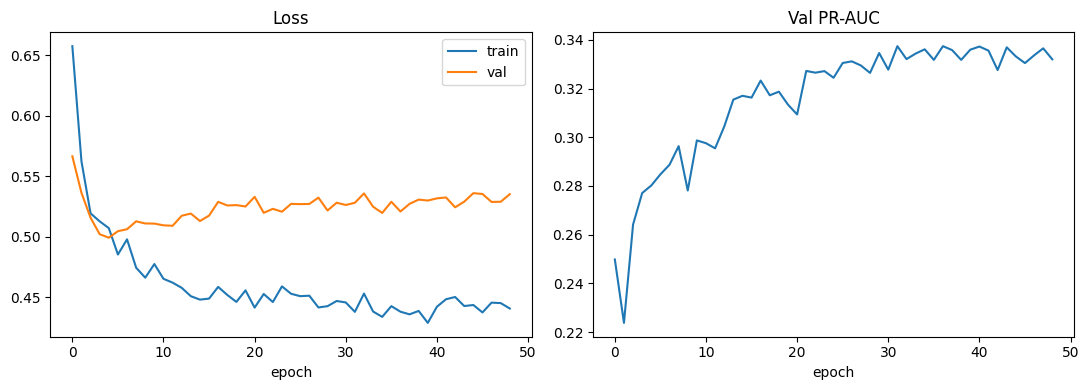

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["tr_loss"], label="train")
ax[0].plot(history["vl_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["vl_pr"])
ax[1].set_title("Val PR-AUC"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## Thresholdni tanlash

In [19]:
from sklearn.metrics import precision_recall_curve

vl_probs,vl_gt,_=get_probs(x_val_dl)
prec,rec,thr=precision_recall_curve(vl_gt,vl_probs)
f1=2*prec[:-1]*rec[:-1]/(prec[:-1]+rec[:-1]+(1e-9))

thr_f1 = thr[f1.argmax()]        # Precision va Recall ortasidagi eng yaxshi balance
ok=np.where(rec[:-1]>=0.80)[0] # Recall >= 0.80  bolgan nuqtalar
thr_rec=thr[ok[-1]] if len(ok) else thr_f1

print("Threshold (F1):", round(float(thr_f1), 3))
print("Threshold (Recall>=0.80):", round(float(thr_rec), 3))

best_thr = thr_rec


Threshold (F1): 0.727
Threshold (Recall>=0.80): 0.684


## Testni baholash


              precision    recall  f1-score   support

           0      0.971     0.883     0.925       486
           1      0.174     0.480     0.255        25

    accuracy                          0.863       511
   macro avg      0.572     0.681     0.590       511
weighted avg      0.932     0.863     0.892       511

PR-AUC : 0.186
ROC-AUC: 0.787


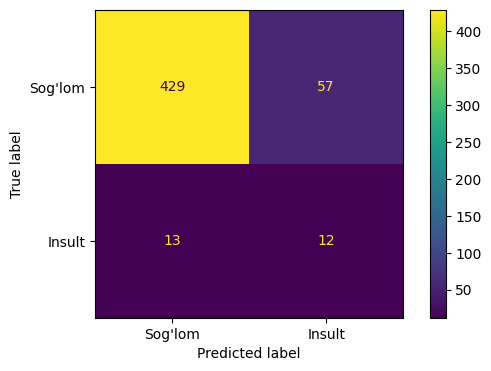

In [20]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             average_precision_score, roc_auc_score,
                             ConfusionMatrixDisplay)

ts_probs, ts_gt, _ = get_probs(x_test_dl)
ts_pred = (ts_probs >= best_thr).astype(int)

print(classification_report(ts_gt, ts_pred, digits=3))
print("PR-AUC :", round(average_precision_score(ts_gt, ts_probs), 3))
print("ROC-AUC:", round(roc_auc_score(ts_gt, ts_probs), 3))

ConfusionMatrixDisplay(confusion_matrix(ts_gt, ts_pred),
                       display_labels=["Sog'lom", "Insult"]).plot()
plt.show()

In [21]:
import json
from sklearn.metrics import precision_score, recall_score, f1_score

results_dl = {
    "model": "MLP (DL)",
    "threshold": float(best_thr),
    "precision": float(precision_score(ts_gt, ts_pred)),
    "recall": float(recall_score(ts_gt, ts_pred)),
    "f1": float(f1_score(ts_gt, ts_pred)),
    "pr_auc": float(average_precision_score(ts_gt, ts_probs)),
    "roc_auc": float(roc_auc_score(ts_gt, ts_probs)),
}
json.dump(results_dl, open("results_mlp.json", "w"), indent=2)

# ML LogisticRegression

In [24]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, average_precision_score,
                             roc_auc_score, confusion_matrix)
                             

y_tr, y_vl, y_ts = np.array(y_train), np.array(y_val), np.array(y_test)
lr=LogisticRegression(class_weight="balanced",max_iter=1000)
lr.fit(x_train,y_tr)

ts_probs_lr=lr.predict_proba(x_test)[:,-1]  #insult extimoli
ts_pred_lr=(ts_probs_lr>=0.5).astype(int)  #hozircha oddiy 0.5

print(classification_report(y_ts, ts_pred_lr, digits=3))
print("PR-AUC :", round(average_precision_score(y_ts, ts_probs_lr), 3))
print("ROC-AUC:", round(roc_auc_score(y_ts, ts_probs_lr), 3))
print(confusion_matrix(y_ts, ts_pred_lr))

              precision    recall  f1-score   support

           0      0.981     0.753     0.852       486
           1      0.130     0.720     0.221        25

    accuracy                          0.751       511
   macro avg      0.556     0.737     0.537       511
weighted avg      0.940     0.751     0.821       511

PR-AUC : 0.237
ROC-AUC: 0.805
[[366 120]
 [  7  18]]


In [29]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

#Random Forest
rf=RandomForestClassifier(n_estimators=300,min_samples_leaf=5,class_weight="balanced_subsample",random_state=42,n_jobs=-1)

y_tr, y_vl, y_ts = np.array(y_train), np.array(y_val), np.array(y_test)

rf.fit(x_train,y_tr)
ts_probs_rf=rf.predict_proba(x_test)[:,1]

# XGBoost
scale_pos=(y_tr==0).sum()/(y_tr==1).sum()   #19.5 DL dagi weight bilan bir hil goya
xgb=XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                    scale_pos_weight=scale_pos, eval_metric="aucpr",
                    random_state=42)

xgb.fit(x_train, y_tr)
ts_probs_xgb = xgb.predict_proba(x_test)[:, 1]

## Comparison

In [30]:
import pandas as pd

assert (ts_gt == y_ts).all()   # DL va ML test tartibi bir xilligini tekshirish

all_probs = {
    "MLP (DL)": ts_probs,
    "LogReg": ts_probs_lr,
    "RandomForest": ts_probs_rf,
    "XGBoost": ts_probs_xgb,
}

rows = []
for name, p in all_probs.items():
    rows.append({"model": name,
                 "PR-AUC": average_precision_score(y_ts, p),
                 "ROC-AUC": roc_auc_score(y_ts, p)})

comparison = pd.DataFrame(rows).set_index("model").round(3)
print(comparison)
comparison.to_csv("comparison.csv")

              PR-AUC  ROC-AUC
model                        
MLP (DL)       0.186    0.787
LogReg         0.237    0.805
RandomForest   0.177    0.806
XGBoost        0.215    0.802


## Cross Validation

In [31]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import pandas as pd

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
spw = (y == 0).sum() / (y == 1).sum()

cv_models = {
    "LogReg": LogisticRegression(class_weight="balanced", max_iter=1000),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        scale_pos_weight=spw, eval_metric="aucpr", random_state=42),
}

rows = []
for name, m in cv_models.items():
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), m)
    res = cross_validate(pipe, x, y, cv=cv,
                         scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
    rows.append({"model": name,
                 "PR-AUC": f"{res['test_pr_auc'].mean():.3f} ± {res['test_pr_auc'].std():.3f}",
                 "ROC-AUC": f"{res['test_roc_auc'].mean():.3f} ± {res['test_roc_auc'].std():.3f}"})

cv_table = pd.DataFrame(rows).set_index("model")
print(cv_table)
cv_table.to_csv("cv_comparison.csv")

                     PR-AUC        ROC-AUC
model                                     
LogReg        0.200 ± 0.028  0.837 ± 0.017
RandomForest  0.184 ± 0.025  0.835 ± 0.017
XGBoost       0.196 ± 0.030  0.823 ± 0.014
